# 01 · Data analysis of the benchmark log

**Project:** professional burnout of teachers in private and state schools (analysis pipeline).
**Question of this notebook:** how do latency and throughput of the analysis script change when the number of
processed respondents grows (n = 35, 100, 1000)?

The notebook follows the four required steps:

1. Data ingestion and warm-up filtering
2. Statistical aggregation (median, p95, p99, 95 % bootstrap CI, error rate as guardrail)
3. Visualization and export to `reports/figures/`
4. Reproducibility checks (fixed seed 42)

All heavy logic lives in `src/process_data.py` and `src/visualize.py`; the notebook only calls it and explains
the results, so the notebook and the command-line scripts can never disagree.

## 0. Setup and fixed random seed

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

SEED = 42
np.random.seed(SEED)  # global seed; the bootstrap below also uses its own default_rng(SEED)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import process_data as pdt
import visualize as viz

pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
print("project root folder:", ROOT.name)
print("pandas", pd.__version__, "| numpy", np.__version__, "| seed", SEED)

project root folder: repo
pandas 2.2.2 | numpy 1.26.4 | seed 42


## 1. Data ingestion and warm-up filtering

The raw log `data/raw/test_run.jsonl` has one JSON object per line: a `meta` line, then the runs
(`phase` = `warmup`, `measure` or `edge`), then a `summary` line. The first executions are **cold**
(imports, caches, lazy initialisation), so they are slower than steady state and must not enter the statistics.

In [2]:
meta, raw, _summary = pdt.load_jsonl(ROOT / "data" / "raw" / "test_run.jsonl")
print("run_id:", meta.get("run_id"), "| seed in log:", meta.get("seed"))
print()
print("Rows per phase:")
print(raw["phase"].value_counts().to_string())
pdt.validate_runs(raw, meta)   # raises if the log is damaged; prints nothing when it is fine
print("\nvalidation passed")

run_id: 32507308 | seed in log: 42

Rows per phase:
phase
measure    120
edge        30
warmup      10

validation passed


Let us look at the evidence that warm-up runs really are different, before removing them.

In [3]:
raw = raw.assign(duration_ms=raw["duration_us"] / 1000.0)
warm = raw[raw["phase"] == "warmup"]
meas = raw[raw["phase"] == "measure"]

print("Warm-up runs, in execution order (ms):")
print(warm[["seq", "workload_n", "duration_ms"]].to_string(index=False))
print()
cmp = pd.DataFrame({
    "warm-up (median, ms)": warm.groupby("workload_n")["duration_ms"].median(),
    "measured (median, ms)": meas.groupby("workload_n")["duration_ms"].median(),
})
cmp["warm-up / measured"] = cmp["warm-up (median, ms)"] / cmp["measured (median, ms)"]
cmp

Warm-up runs, in execution order (ms):
 seq  workload_n  duration_ms
   0          35       70.777
   1         100       70.379
   2        1000       66.417
   3          35      114.703
   4         100       69.301
   5        1000       69.408
   6          35       68.564
   7         100       59.975
   8        1000       77.568
   9          35       59.478



,"warm-up (median, ms)","measured (median, ms)",warm-up / measured
workload_n,,,
35,69.671,43.910,1.587
100,69.301,43.805,1.582
1000,69.408,46.793,1.483


The comparison above is the justification for discarding the warm-up phase. Now we apply the cleaning rules
of `process_data.clean`: warm-up rows are removed (and counted), edge-case rows are analysed separately,
and outliers are only **flagged** (Tukey fences, 1.5 × IQR), never deleted.

In [4]:
res = pdt.clean(raw.drop(columns=["duration_ms"]))
measured = res["measured"]
print(f"warm-up rows removed : {res['n_warmup_removed']}")
print(f"measured runs kept   : {len(measured)}")
print(f"edge-case rows       : {len(res['edge'])} (analysed separately)")
print(f"IQR outliers flagged : {int(measured['is_outlier_iqr'].sum())} (kept in the statistics)")

warm-up rows removed : 10
measured runs kept   : 120
edge-case rows       : 30 (analysed separately)
IQR outliers flagged : 9 (kept in the statistics)


### Guardrail metric: error rate

Errors are never dropped silently. The error rate is computed over **all** measured runs (ok + error), so
failures cannot bias the latency sample (selection bias). A latency improvement that comes with more errors
would be fake.

In [5]:
res['guardrail']

,n_runs,n_ok,n_error,n_http_error,error_rate
workload_n,,,,,
all,120.000,120.000,0.000,0.000,0.000
35,40.000,40.000,0.000,0.000,0.000
100,40.000,40.000,0.000,0.000,0.000
1000,40.000,40.000,0.000,0.000,0.000


## 2. Statistical aggregation

Latency is right-skewed, so the **median** and the percentiles **p95** and **p99** are the primary
summaries; mean and SD are reported for completeness. Uncertainty is quantified with a **percentile bootstrap**:
10 000 resamples of the 40 runs per workload, 95 % interval (2.5 % and 97.5 % quantiles), seed 42.

In [6]:
metrics = pdt.compute_metrics(measured, seed=SEED)

lat = metrics[["workload_n", "n_ok", "error_rate", "latency_ms_p50", "latency_ms_p50_ci_lo",
               "latency_ms_p50_ci_hi", "latency_ms_p95", "latency_ms_p99"]].copy()
lat.columns = ["n", "runs", "error rate", "p50 (ms)", "p50 CI lo", "p50 CI hi", "p95 (ms)", "p99 (ms)"]
lat

,n,runs,error rate,p50 (ms),p50 CI lo,p50 CI hi,p95 (ms),p99 (ms)
0,35,40,0.000,43.910,43.007,44.619,53.829,64.108
1,100,40,0.000,43.805,43.045,45.113,53.285,59.014
2,1000,40,0.000,46.793,46.170,47.888,55.329,82.086
3,all,120,0.000,45.069,44.112,45.896,53.758,70.048


In [7]:
thr = metrics[metrics["workload_n"] != "all"][["workload_n", "throughput_rps_p50", "throughput_rps_p50_ci_lo",
                                               "throughput_rps_p50_ci_hi"]].copy()
thr.columns = ["n", "throughput p50 (resp./s)", "CI lo", "CI hi"]

# speed-up S(n) = median throughput relative to the baseline n0 = 35, efficiency E(n) = S(n) / (n / n0)
n_int = thr["n"].astype(int)
thr["S(n)"] = thr["throughput p50 (resp./s)"] / thr["throughput p50 (resp./s)"].iloc[0]
thr["E(n)"] = thr["S(n)"] / (n_int / n_int.iloc[0])
thr

,n,throughput p50 (resp./s),CI lo,CI hi,S(n),E(n)
0,35,797.086,784.421,813.844,1.000,1.000
1,100,"2,282.874","2,216.809","2,323.155",2.864,1.002
2,1000,"21,371.191","20,882.140","21,658.877",26.812,0.938


**Reading the numbers.** The median latency stays between about 44 and 47 ms for a workload that is 28 times
larger, while the median throughput grows from about 800 to about 21 000 respondents per second. The p99 is the
least certain quantity: with 40 runs it is determined by the one or two slowest runs, so its interval is wide.

## 3. Reproducibility checks

Two checks: (i) running the aggregation twice with the same seed gives identical tables, (ii) our result equals
the committed file `data/processed/metrics_summary.csv` (written by the command-line script).

In [8]:
again = pdt.compute_metrics(measured, seed=SEED)
pd.testing.assert_frame_equal(metrics, again)
print("check 1 OK: same seed -> identical metrics")

committed = pd.read_csv(ROOT / "data" / "processed" / "metrics_summary.csv", dtype={"workload_n": str})
num = metrics.select_dtypes("number").columns
np.testing.assert_allclose(metrics[num].to_numpy(float), committed[num].to_numpy(float), rtol=1e-5, equal_nan=True)
print("check 2 OK: notebook == data/processed/metrics_summary.csv (rtol 1e-5)")

check 1 OK: same seed -> identical metrics
check 2 OK: notebook == data/processed/metrics_summary.csv (rtol 1e-5)


## 4. Visualization and export

Figures follow the three rules of scientific graphics: explicit axes with units (and a log scale where the
values span an order of magnitude), shaded 95 % CI bands or error bars, and a colour-blind-safe palette with
different line styles and markers. Each figure is saved as vector `.pdf` and as `.png` with 300 DPI.

In [9]:
import matplotlib.pyplot as plt

fig_dir = ROOT / "reports" / "figures"
palette = viz.set_publication_style()
m_plot, r_plot = viz.load_inputs(viz.METRICS_CSV, viz.RUNS_CSV)

written = []
written += viz.save_figure(viz.plot_latency_vs_workload(m_plot, palette), "fig1_latency_vs_load", fig_dir)
written += viz.save_figure(viz.plot_latency_distribution(r_plot, m_plot, palette), "fig2_distribution_boxplot", fig_dir)
for p in written:
    print("saved", p.relative_to(ROOT))

saved reports/figures/fig1_latency_vs_load.pdf
saved reports/figures/fig1_latency_vs_load.png
saved reports/figures/fig2_distribution_boxplot.pdf
saved reports/figures/fig2_distribution_boxplot.png


### Figure 1: latency percentiles and throughput versus workload

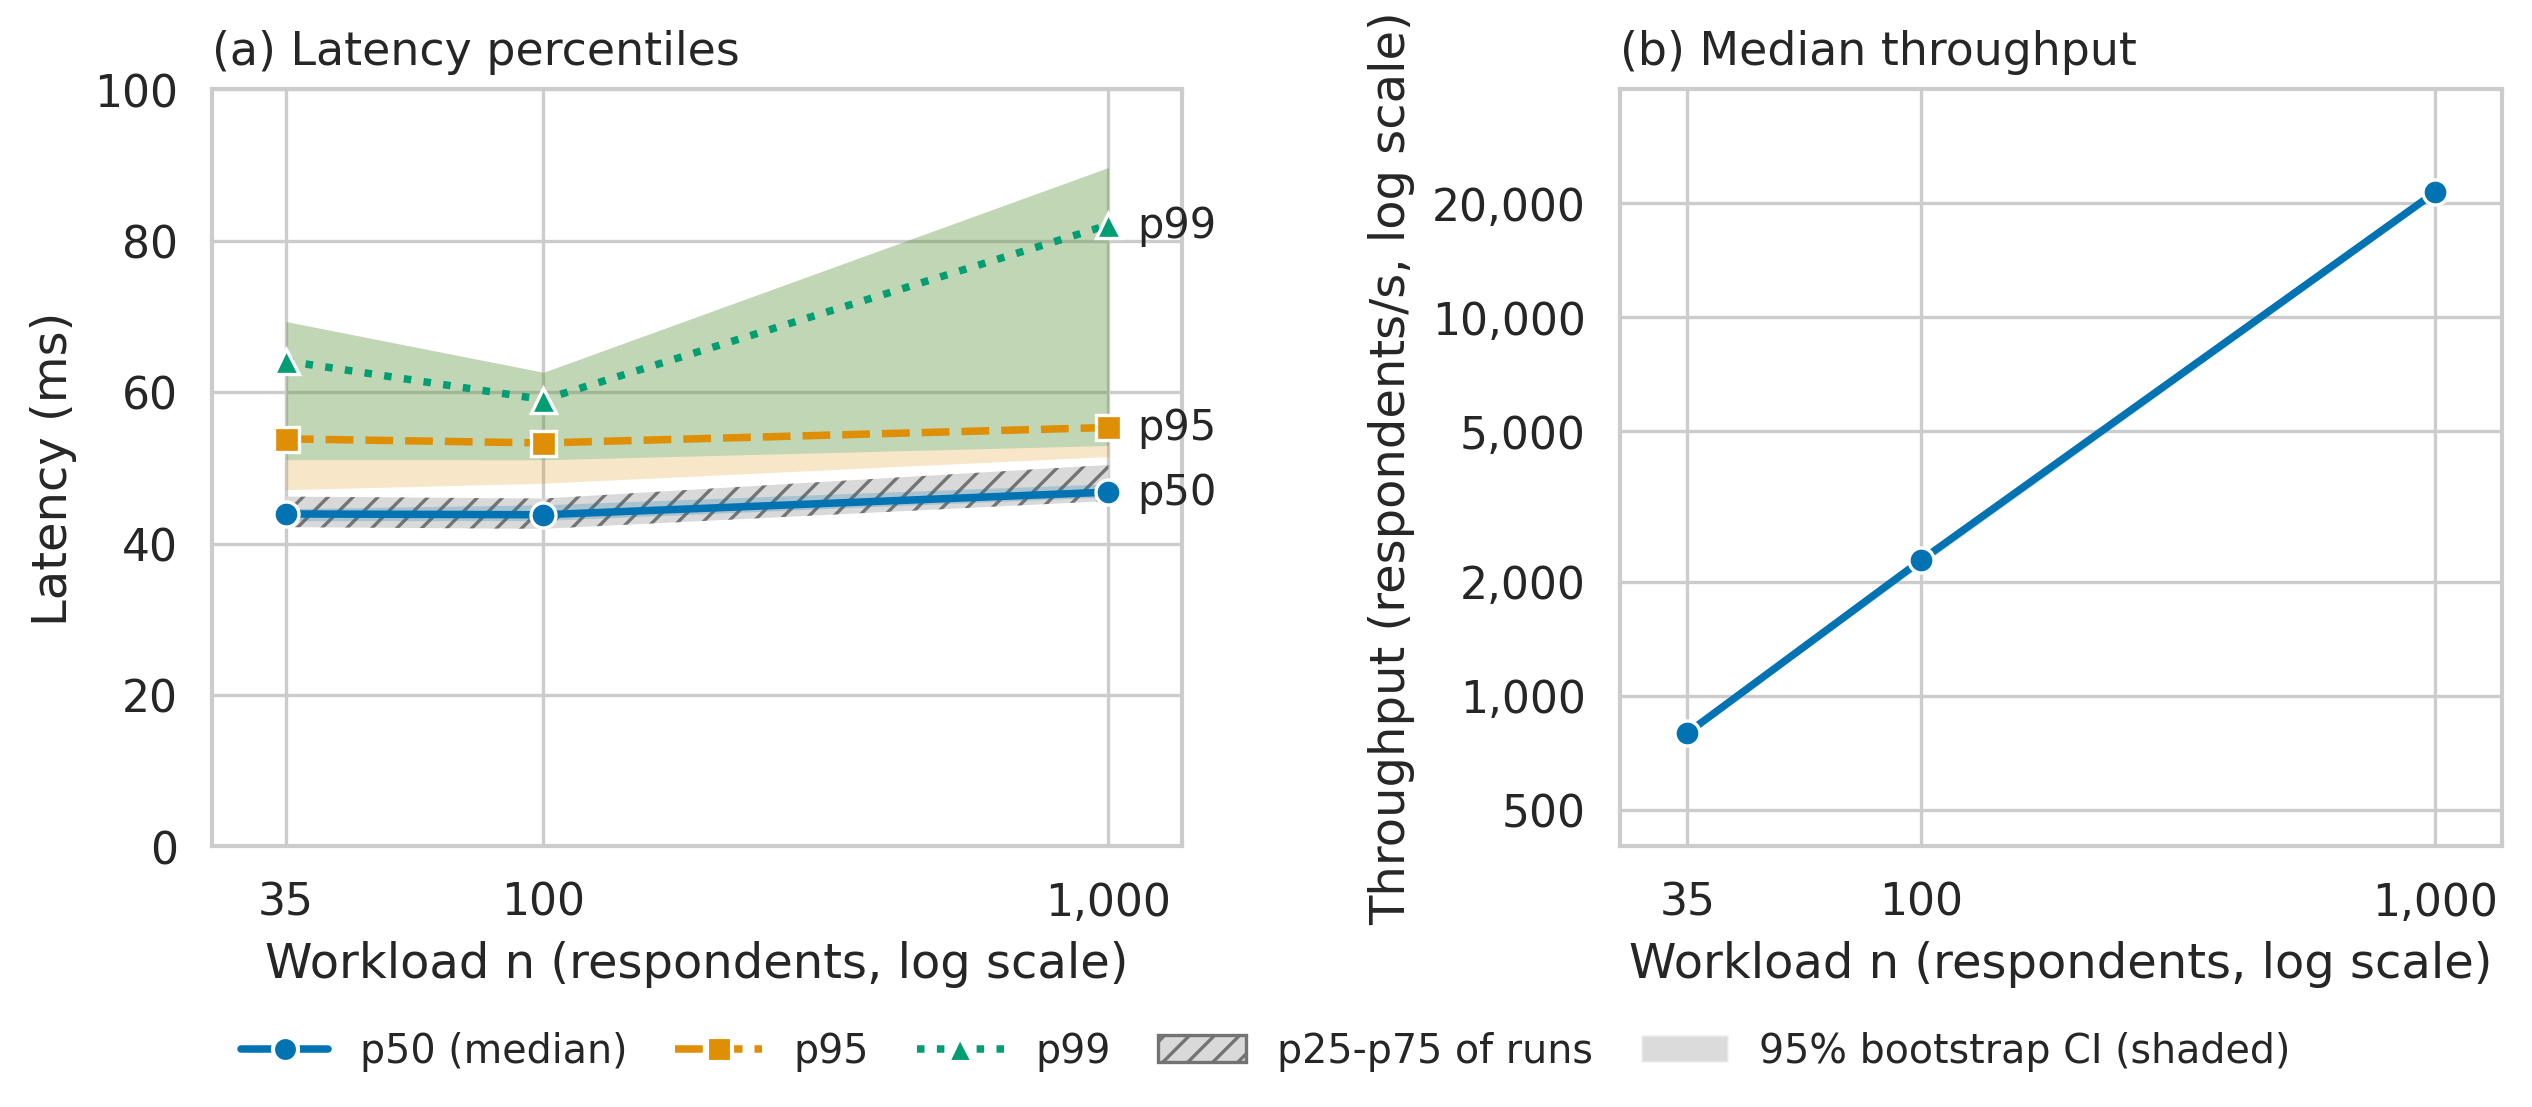

In [10]:
display(Image(filename=str(fig_dir / 'fig1_latency_vs_load.png'), width=900))

Coloured bands are the 95 % bootstrap CIs, the grey hatched band is p25–p75 of the runs. The p99 band is wide
because of the small number of runs; the p50 and p95 are tight.

### Figure 2: distribution of single runs

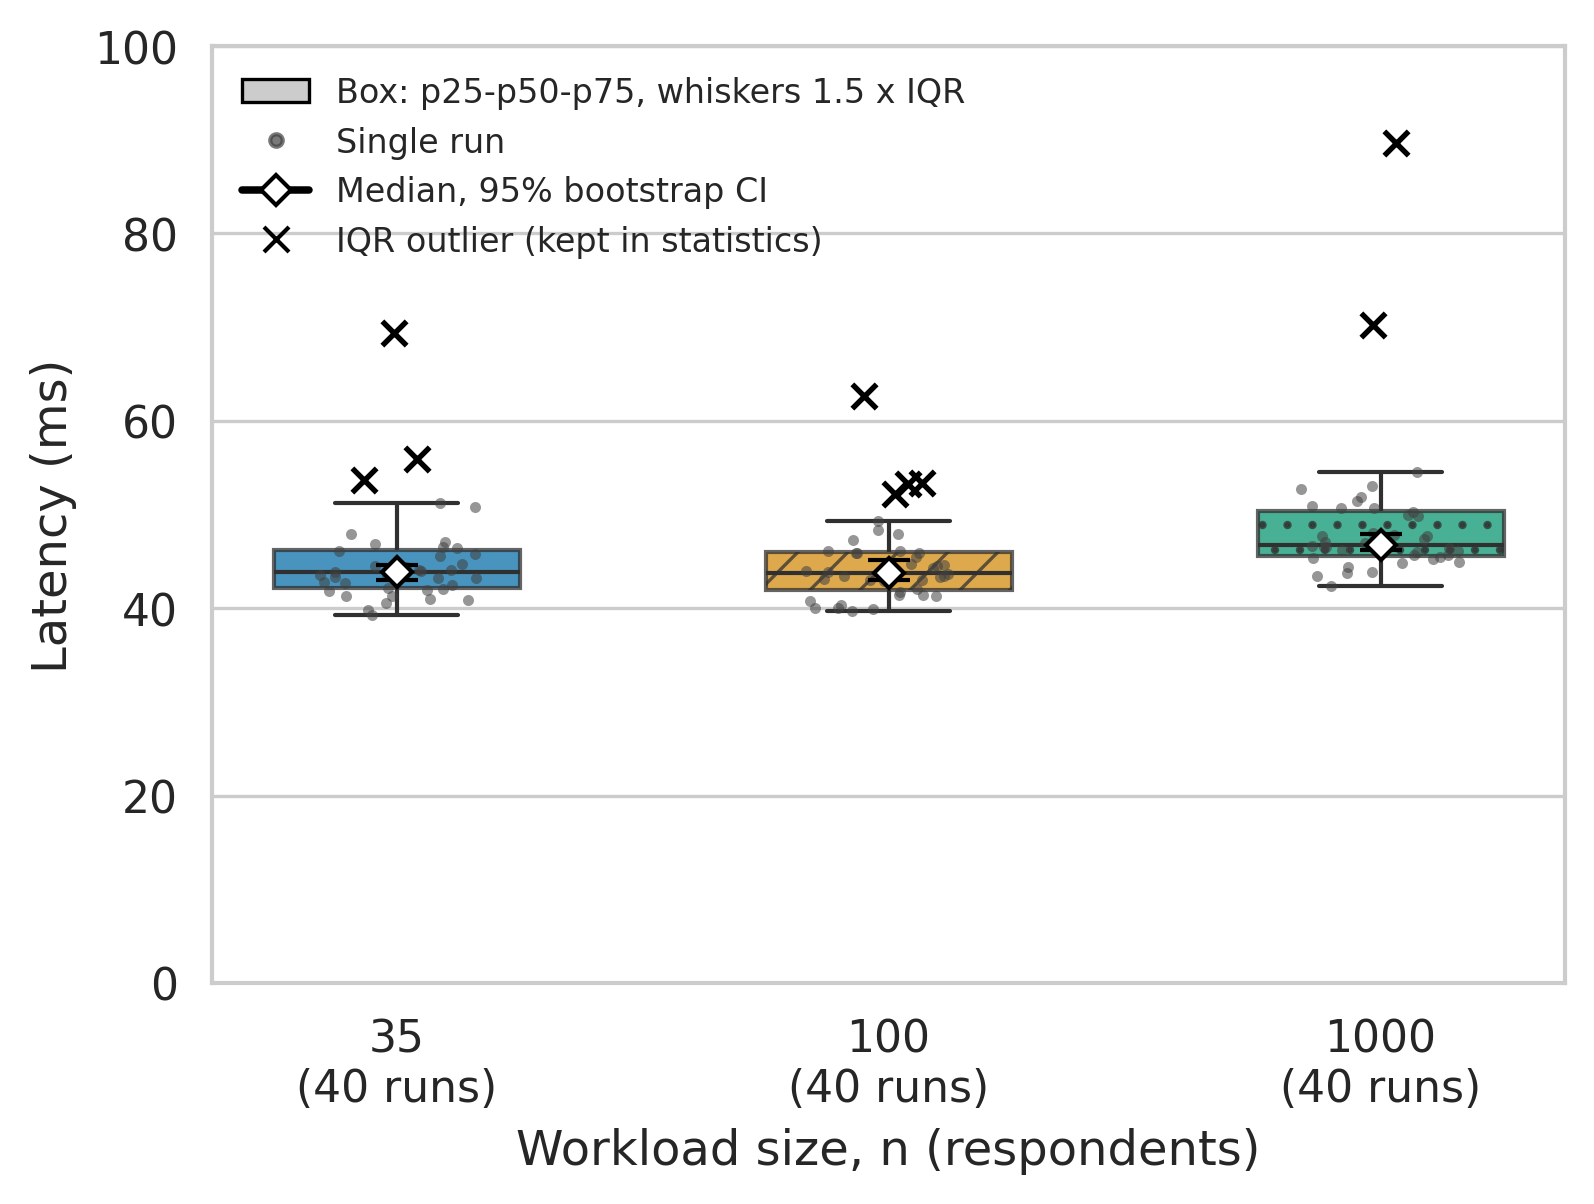

In [11]:
display(Image(filename=str(fig_dir / 'fig2_distribution_boxplot.png'), width=520))

Boxes show p25, p50, p75; the white diamond is the median with its 95 % CI. Crosses are IQR outliers, which are
real slow runs and therefore stay in the statistics.

In [12]:
from PIL import Image as PILImage
for name in ["fig1_latency_vs_load", "fig2_distribution_boxplot"]:
    png = PILImage.open(fig_dir / f"{name}.png")
    pdf_ok = (fig_dir / f"{name}.pdf").stat().st_size > 0
    print(f"{name}: PNG {png.size[0]}x{png.size[1]} px at {round(png.info['dpi'][0])} DPI, vector PDF present: {pdf_ok}")

fig1_latency_vs_load: PNG 2532x1107 px at 300 DPI, vector PDF present: True
fig2_distribution_boxplot: PNG 1594x1204 px at 300 DPI, vector PDF present: True


## 5. Conclusions

* **No errors:** 0 of 120 measured runs failed, so the guardrail metric is clean.
* **Latency is almost flat:** the medians for 35 and 100 respondents are statistically indistinguishable;
  1000 respondents is about 3 ms slower, with a non-overlapping interval.
* **Throughput scales almost linearly** (efficiency E(1000) ≈ 0.94).
* **Limits:** one machine, synthetic respondents, 40 runs per size (imprecise p99).